### Validação de Clusters: DBSCAN

O DBSCAN não recebe o número de clusters como parâmetro; ele depende de **`eps`** (raio de vizinhança) e **`min_samples`** (nº mínimo de pontos para formar uma região densa). A justificativa segue duas etapas:

1. **`min_samples`**: seguimos a heurística de Sander et al. (1998), amplamente adotada na literatura — `min_samples ≥ D + 1`, sendo `D` o número de dimensões (variáveis). Para dados com ruído, recomenda-se `min_samples ≈ 2×D`. Como temos 21 variáveis, testamos os dois extremos dessa faixa (`D+1 = 22` e `2×D = 42`).
2. **`eps`**: usamos o **gráfico de distância ao k-ésimo vizinho** (k = `min_samples`), ordenado de forma crescente. O ponto de maior curvatura ("cotovelo") do gráfico indica o valor de `eps` que separa pontos densos (dentro de clusters) de pontos esparsos (ruído).

In [20]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

base_path = Path.cwd().parent
file_path = base_path / "data" / "processed" / "Base_de_Dados_Treino.csv"

df = pd.read_csv(file_path, index_col="id_municipio")

df.head()

,População_2022,Pontuação Indice ODS 2025,Goal 1 Score,Goal 2 Score,Goal 3 Score,Goal 5 Score,Goal 6 Score,Goal 7 Score,Goal 8 Score,Goal 9 Score,...,Normalizado (0-100): SDG15_8_UNI_CNS,Normalizado (0-100): SDG15_PRTAMB,Normalizado (0-100): SDG16_1_OB_HM,Normalizado (0-100): SDG16_3_M_ARM_FG,Normalizado (0-100): SDG16_4_TX_HMC,Normalizado (0-100): SDG16_CRP,Normalizado (0-100): SDG16_DRTHMN,Normalizado (0-100): SDG16_TRANSP,Normalizado (0-100): SDG17_1_INVST_PB,Normalizado (0-100): SDG17_3_P_RC_TRB
id_municipio,,,,,,,,,,,,,,,,,,,,,
3918,13909.0,53.269415,59.155521,38.091787,64.289521,59.669159,64.310097,83.218333,45.514930,9.682504,...,0.000,80.0,0.0,0.0,43.239474,57.143,42.857,50.000,10.124436,13.564593
3986,21079.0,55.585523,46.276918,42.283804,69.059248,67.296407,60.647976,85.062037,55.873860,8.445009,...,0.000,80.0,100.0,0.0,75.039474,71.429,57.143,66.667,16.432705,15.811404
2758,8179.0,55.058278,50.879872,49.291735,71.076996,53.381715,60.523228,91.672593,61.346097,5.863289,...,0.021,80.0,100.0,100.0,100.000000,71.429,28.571,66.667,65.825616,21.501196
4797,2526.0,55.060949,62.635812,38.882979,72.896892,60.433893,66.063390,72.817500,58.852291,23.074656,...,0.000,80.0,100.0,100.0,100.000000,85.714,28.571,66.667,41.141996,7.627592
4504,6716.0,50.710311,46.935921,39.611815,78.407745,72.821067,60.823721,70.107870,56.257037,16.999769,...,0.000,60.0,100.0,100.0,100.000000,85.714,57.143,66.667,12.527347,10.809410


#### Separação das features escolhidas

In [21]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

import json

with open(base_path / "data" / "processed" / "features_perfil.json", encoding="utf-8") as f:
    features_perfil = json.load(f)

X_perfil = df[features_perfil].copy()

imputer_perfil = SimpleImputer(strategy='median')
X_perfil_imputed = pd.DataFrame(imputer_perfil.fit_transform(X_perfil), columns=features_perfil)

scaler_perfil = StandardScaler()
X_perfil_scaled = scaler_perfil.fit_transform(X_perfil_imputed)

> **Nota de revisão 3:** mesmo com a varredura ampla de `eps` (percentil 1 a 99), a melhor combinação sem nenhum limite de ruído ainda ficou com ~74% dos municípios classificados como ruído — usando `min_samples = 23` e `44` (`D+1` e `2×D`, com `D = 22` variáveis). Isso é um sintoma clássico de maldição da dimensionalidade: em ~22 dimensões, exigir 23-44 vizinhos dentro do mesmo raio é uma barra alta demais para a maioria dos municípios atingir, então o algoritmo alterna entre "quase tudo ruído" (eps pequeno) e "quase tudo um cluster só" (eps grande), sem um meio-termo real. `min_samples` bem menores (5, 10) relaxam essa exigência de densidade e são comuns na prática para dados de mais de ~15 dimensões — testamos os dois regimes lado a lado abaixo.

In [22]:
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
import numpy as np 

n_features = len(features_perfil)

candidatos_min_samples = sorted(set([5, 10, n_features + 1, 2 * n_features]))

def encontrar_eps_cotovelo(X, k):
    """Detecta o ponto de maior curvatura no gráfico de distância ao k-ésimo vizinho
    (método do 'kneedle': ponto mais distante da reta que liga o primeiro e o último ponto)."""
    nn = NearestNeighbors(n_neighbors=k).fit(X)
    distancias, _ = nn.kneighbors(X)
    k_distancias = np.sort(distancias[:, -1])

    x = np.arange(len(k_distancias))
    x_norm = (x - x.min()) / (x.max() - x.min())
    y_norm = (k_distancias - k_distancias.min()) / (k_distancias.max() - k_distancias.min())

    vetor_linha = np.array([x_norm[-1] - x_norm[0], y_norm[-1] - y_norm[0]])
    vetor_linha = vetor_linha / np.linalg.norm(vetor_linha)

    vetores_pontos = np.stack([x_norm - x_norm[0], y_norm - y_norm[0]], axis=1)
    proj_comprimento = vetores_pontos @ vetor_linha
    projecao = np.outer(proj_comprimento, vetor_linha)
    distancia_ate_reta = np.linalg.norm(vetores_pontos - projecao, axis=1)

    idx_cotovelo = int(np.argmax(distancia_ate_reta))
    return k_distancias, idx_cotovelo, k_distancias[idx_cotovelo]

eps_estimado_por_minsamples = {}
for ms in candidatos_min_samples:
    k_dist, idx_cotovelo, eps_est = encontrar_eps_cotovelo(X_perfil_scaled, ms)
    eps_estimado_por_minsamples[ms] = (k_dist, idx_cotovelo, eps_est)
    print(f"min_samples = {ms:>3} -> eps estimado (cotovelo) = {eps_est:.3f}")

min_samples =   5 -> eps estimado (cotovelo) = 5.162
min_samples =  10 -> eps estimado (cotovelo) = 5.623
min_samples =  25 -> eps estimado (cotovelo) = 6.238
min_samples =  48 -> eps estimado (cotovelo) = 6.587


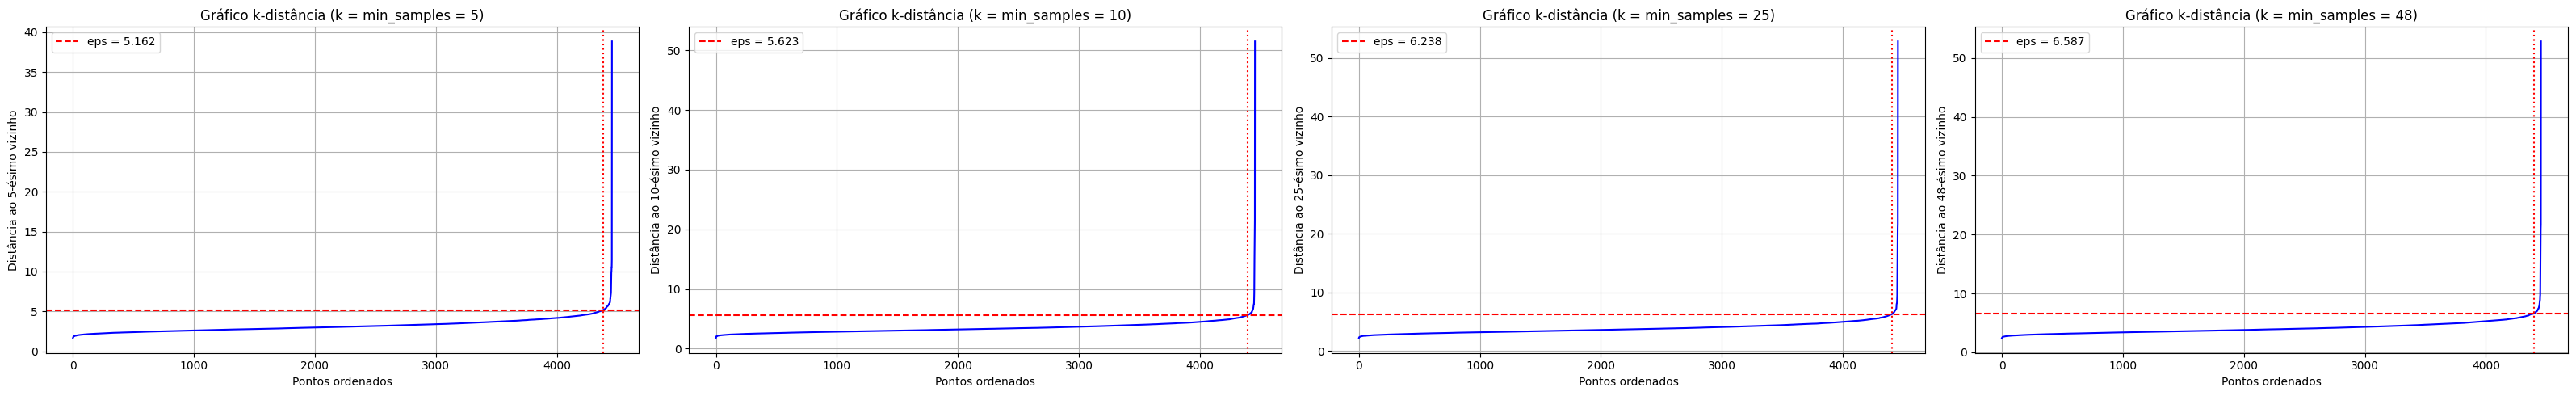

In [23]:
fig, axes = plt.subplots(1, len(candidatos_min_samples), figsize=(8 * len(candidatos_min_samples), 5))

for ax, ms in zip(np.atleast_1d(axes), candidatos_min_samples):
    k_dist, idx_cotovelo, eps_est = eps_estimado_por_minsamples[ms]
    ax.plot(k_dist, color='b')
    ax.axhline(eps_est, color='r', linestyle='--', label=f'eps = {eps_est:.3f}')
    ax.axvline(idx_cotovelo, color='r', linestyle=':')
    ax.set_title(f'Gráfico k-distância (k = min_samples = {ms})')
    ax.set_xlabel('Pontos ordenados')
    ax.set_ylabel(f'Distância ao {ms}-ésimo vizinho')
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

### Varredura de `eps` ao longo de toda a curva k-distância

A primeira versão testava uma faixa estreita em torno do cotovelo estimado (0.3×–2.0×). Isso funciona quando o cotovelo está bem localizado, mas nos dados reais a região com 2+ clusters pode estar **fora** dessa faixa — foi o que aconteceu aqui: nem relaxando o filtro de ruído apareceu nenhuma combinação válida.

Em vez de depender da heurística do cotovelo acertar o centro da faixa, varremos quase toda a curva k-distância observada (do percentil 1 ao percentil 99 das distâncias, em escala log — cobre várias ordens de grandeza de uma vez, do regime "tudo ruído" ao regime "um cluster só", capturando qualquer região intermediária de multi-cluster que exista entre os dois extremos, onde quer que ela esteja).

In [24]:
resultados_dbscan = []

for ms in candidatos_min_samples:
    k_dist_completo, _, _ = eps_estimado_por_minsamples[ms]

    eps_min = np.percentile(k_dist_completo, 1)
    eps_max = np.percentile(k_dist_completo, 99)
    eps_min = max(eps_min, k_dist_completo[k_dist_completo > 0].min() * 0.5)

    faixa_eps = np.geomspace(eps_min, eps_max, 40)

    for eps in faixa_eps:
        labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_perfil_scaled)

        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_ruido = int((labels == -1).sum())
        frac_ruido = n_ruido / len(labels)

        sil = np.nan
        tamanho_min_cluster = 0
        if n_clusters >= 2:
            mascara_valida = labels != -1
            if mascara_valida.sum() > n_clusters:
                sil = silhouette_score(X_perfil_scaled[mascara_valida], labels[mascara_valida])
            # tamanho do MENOR cluster real (exclui ruido) -- evita escolher um "cluster" de poucos pontos
            contagens = pd.Series(labels[mascara_valida]).value_counts()
            tamanho_min_cluster = int(contagens.min())

        resultados_dbscan.append({
            'min_samples': ms,
            'eps': eps,
            'n_clusters': n_clusters,
            'n_ruido': n_ruido,
            'frac_ruido': frac_ruido,
            'tamanho_min_cluster': tamanho_min_cluster,
            'silhouette': sil
        })

df_resultados_dbscan = pd.DataFrame(resultados_dbscan)
display(df_resultados_dbscan)

,min_samples,eps,n_clusters,n_ruido,frac_ruido,tamanho_min_cluster,silhouette
0,5,2.021222,13,4294,0.963645,4,0.171568
1,5,2.073890,15,4223,0.947711,4,0.129504
2,5,2.127930,18,4130,0.926840,4,0.039996
3,5,2.183378,19,3989,0.895197,3,-0.038350
4,5,2.240271,15,3860,0.866248,2,-0.087937
...,...,...,...,...,...,...,...
155,48,6.210581,1,14,0.003142,0,NaN
156,48,6.355749,1,11,0.002469,0,NaN
157,48,6.504310,1,11,0.002469,0,NaN
158,48,6.656343,1,11,0.002469,0,NaN


Antes de filtrar, vale visualizar como o nº de clusters e a fração de ruído se comportam ao longo da faixa de `eps` testada — isso mostra se existe de fato uma região de equilíbrio entre os dois extremos (tudo ruído vs. um único cluster), ou se é preciso ampliar/deslocar a faixa de busca.

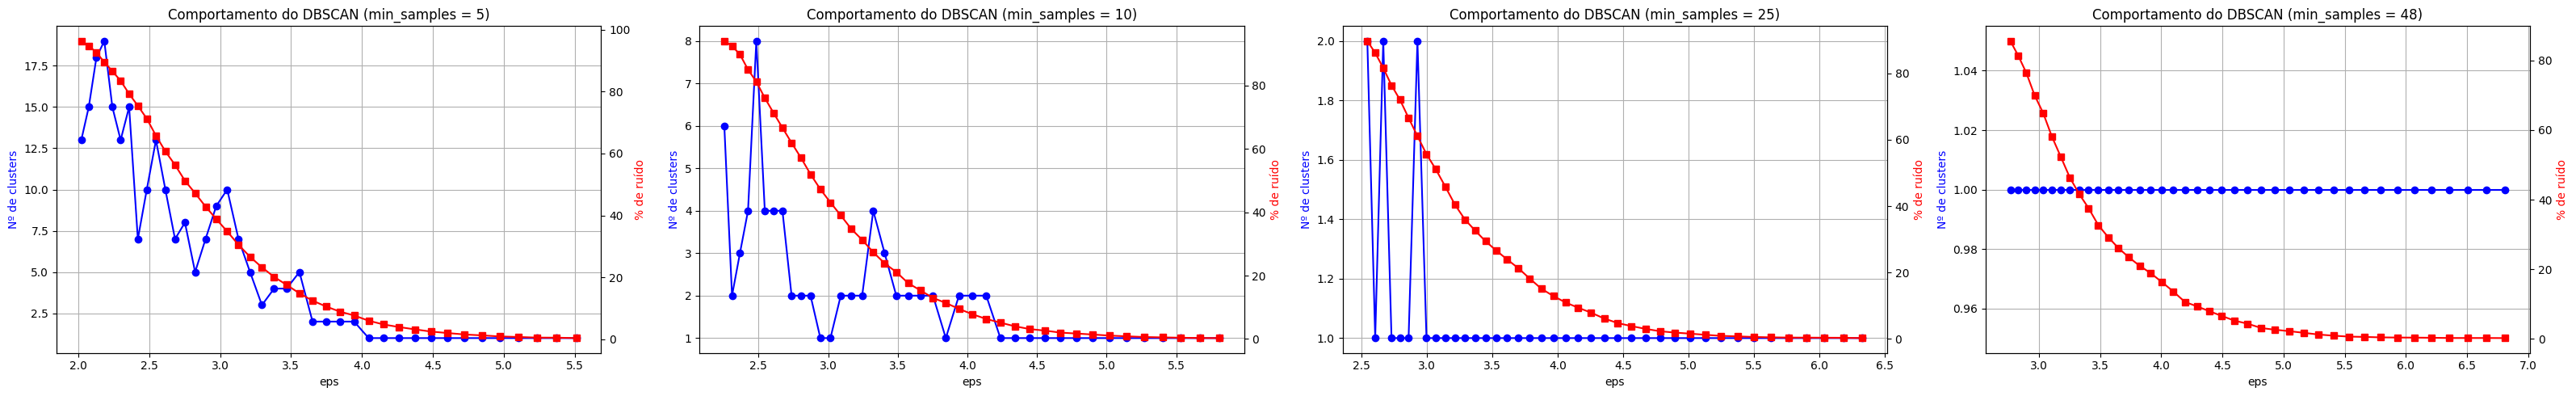

In [25]:
fig, axes = plt.subplots(1, len(candidatos_min_samples), figsize=(8 * len(candidatos_min_samples), 5))

for ax, ms in zip(np.atleast_1d(axes), candidatos_min_samples):
    subset = df_resultados_dbscan[df_resultados_dbscan['min_samples'] == ms]
    ax2 = ax.twinx()

    ax.plot(subset['eps'], subset['n_clusters'], marker='o', color='b', label='Nº de clusters')
    ax2.plot(subset['eps'], subset['frac_ruido'] * 100, marker='s', color='r', label='% ruído')

    ax.set_xlabel('eps')
    ax.set_ylabel('Nº de clusters', color='b')
    ax2.set_ylabel('% de ruído', color='r')
    ax.set_title(f'Comportamento do DBSCAN (min_samples = {ms})')
    ax.grid(True)

plt.tight_layout()
plt.show()

In [26]:
LIMIARES_RUIDO = [0.15, 0.30, 0.50, 1.0]  # 1.0 = sem limite de ruído (mas ainda exige tamanho mínimo)

MIN_FRACAO_CLUSTER = 0.02
TAMANHO_MIN_CLUSTER = max(30, int(len(X_perfil_scaled) * MIN_FRACAO_CLUSTER))
print(f"Tamanho mínimo exigido por cluster: {TAMANHO_MIN_CLUSTER} municípios "
      f"({MIN_FRACAO_CLUSTER:.0%} dos {len(X_perfil_scaled)} municípios)")

df_com_silhouette = df_resultados_dbscan.dropna(subset=['silhouette'])

df_candidatos_validos = pd.DataFrame()
limiar_usado = None

for limiar in LIMIARES_RUIDO:
    candidatos = df_com_silhouette[
        (df_com_silhouette['frac_ruido'] <= limiar) &
        (df_com_silhouette['tamanho_min_cluster'] >= TAMANHO_MIN_CLUSTER)
    ]
    if not candidatos.empty:
        df_candidatos_validos = candidatos
        limiar_usado = limiar
        break

if df_candidatos_validos.empty:
    print(f"Nenhuma combinação atingiu tamanho mínimo de {TAMANHO_MIN_CLUSTER} por cluster, mesmo sem limite de ruído.")
    print("Relaxando também a exigência de tamanho mínimo (mantendo só >= 2 clusters)...")
    df_candidatos_validos = df_com_silhouette
else:
    print(f"Limiar de ruído usado: <= {limiar_usado:.0%} (com tamanho mínimo de {TAMANHO_MIN_CLUSTER} por cluster respeitado)")

if df_candidatos_validos.empty:
    raise ValueError(
        "Nenhuma combinação de eps/min_samples produziu >= 2 clusters nesta faixa de busca. "
        "Amplie a faixa de eps na célula anterior ou revise os candidatos de min_samples."
    )

df_candidatos_validos = df_candidatos_validos.sort_values('silhouette', ascending=False)
display(df_candidatos_validos.head(10))

melhor_combinacao = df_candidatos_validos.iloc[0]
melhor_eps = melhor_combinacao['eps']
melhor_min_samples = int(melhor_combinacao['min_samples'])

print(f"Combinação escolhida: eps = {melhor_eps:.3f}, min_samples = {melhor_min_samples}")
print(f"Clusters formados: {int(melhor_combinacao['n_clusters'])} | "
      f"Ruído: {int(melhor_combinacao['n_ruido'])} municípios ({melhor_combinacao['frac_ruido']:.1%}) | "
      f"Menor cluster: {int(melhor_combinacao['tamanho_min_cluster'])} municípios | "
      f"Silhouette: {melhor_combinacao['silhouette']:.4f}")

if melhor_combinacao['tamanho_min_cluster'] < TAMANHO_MIN_CLUSTER:
    print("\nATENÇÃO: mesmo após relaxar tudo, o menor cluster ficou abaixo do tamanho mínimo desejado.")
    print("Isso é um sinal de que, com os candidatos de min_samples testados, o DBSCAN não encontra uma")
    print("segmentação balanceada nesta base -- vale reconsiderar os candidatos de min_samples ou o próprio")
    print("uso do DBSCAN para estas variáveis.")

Tamanho mínimo exigido por cluster: 89 municípios (2% dos 4456 municípios)
Nenhuma combinação atingiu tamanho mínimo de 89 por cluster, mesmo sem limite de ruído.
Relaxando também a exigência de tamanho mínimo (mantendo só >= 2 clusters)...


,min_samples,eps,n_clusters,n_ruido,frac_ruido,tamanho_min_cluster,silhouette
58,10,3.489063,2,942,0.211400,10,0.384800
59,10,3.574790,2,785,0.176167,10,0.376163
53,10,3.090298,2,1739,0.390260,13,0.374371
60,10,3.662623,2,684,0.153501,10,0.370182
61,10,3.752615,2,578,0.129713,15,0.355857
54,10,3.166227,2,1547,0.347172,19,0.346579
55,10,3.244022,2,1395,0.313061,18,0.342199
63,10,3.939285,2,424,0.095153,10,0.340148
65,10,4.135240,2,282,0.063285,13,0.338676
64,10,4.036073,2,348,0.078097,11,0.338258


Combinação escolhida: eps = 3.489, min_samples = 10
Clusters formados: 2 | Ruído: 942 municípios (21.1%) | Menor cluster: 10 municípios | Silhouette: 0.3848

ATENÇÃO: mesmo após relaxar tudo, o menor cluster ficou abaixo do tamanho mínimo desejado.
Isso é um sinal de que, com os candidatos de min_samples testados, o DBSCAN não encontra uma
segmentação balanceada nesta base -- vale reconsiderar os candidatos de min_samples ou o próprio
uso do DBSCAN para estas variáveis.


#### Agrupamento final (DBSCAN)

In [27]:
dbscan_perfil = DBSCAN(eps=melhor_eps, min_samples=melhor_min_samples)
labels_perfil_dbscan = dbscan_perfil.fit_predict(X_perfil_scaled)

df['Cluster_Perfil_DBSCAN'] = labels_perfil_dbscan

print(f"Grupos formados: {sorted(set(labels_perfil_dbscan))} | "
      f"Ruído: {(labels_perfil_dbscan == -1).sum()} municípios ({(labels_perfil_dbscan == -1).mean():.1%})")

Grupos formados: [np.int64(-1), np.int64(0), np.int64(1)] | Ruído: 942 municípios (21.1%)


#### Análise da média de cada variável por cluster (DBSCAN)

O cluster `-1` corresponde ao ruído (municípios que não se encaixam em nenhuma região densa) — ele é mantido separado na análise, mas deve ser interpretado como "atípicos", não como um perfil coeso.

In [28]:
df_analise_perfis_dbscan = X_perfil_imputed.copy()
df_analise_perfis_dbscan['Cluster'] = labels_perfil_dbscan

resumo_perfis_dbscan = df_analise_perfis_dbscan.groupby('Cluster').mean().round(2)
display(resumo_perfis_dbscan)

df_analise_perfis_dbscan['Cluster'].value_counts().sort_index()

,Goal 12 Score,Goal 13 Score,Goal 15 Score,Goal 2 Score,Normalizado (0-100): SDG10_21_GRV,Normalizado (0-100): SDG10_4_ACEQP,Normalizado (0-100): SDG10_DIF_FEM_NNN,Normalizado (0-100): SDG11_33_M_TRNS,Normalizado (0-100): SDG11_4_P_P_SUBN,Normalizado (0-100): SDG11_6_NGR_SUBN,...,Normalizado (0-100): SDG2_9_AGR_ORG,Normalizado (0-100): SDG3_13_SCD,Normalizado (0-100): SDG3_16_M_MAT,Normalizado (0-100): SDG3_18_T_M_NT,Normalizado (0-100): SDG5_4_P_VRDR,Normalizado (0-100): SDG5_7_JV_NENT,Normalizado (0-100): SDG6_1_IN_DRSAI,Normalizado (0-100): SDG6_8_CLT_DML,Normalizado (0-100): SDG8_2_OCP_INF,Pontuação Indice ODS 2025
Cluster,,,,,,,,,,,,,,,,,,,,,
-1,72.77,64.15,25.32,47.17,57.14,91.23,75.76,66.08,88.75,0.25,...,11.66,72.73,84.48,69.95,17.00,46.73,73.34,73.05,60.76,48.57
0,72.46,67.46,22.12,46.43,57.19,99.36,85.13,67.10,97.98,0.00,...,4.07,78.53,97.06,78.79,3.88,43.82,77.63,78.15,60.04,50.42
1,61.47,76.17,31.23,46.68,70.40,3.32,88.44,76.42,95.06,0.00,...,18.38,82.49,92.42,75.20,0.38,59.69,86.43,96.38,72.62,55.91


Cluster
-1     942
 0    3504
 1      10
Name: count, dtype: int64

#### Mapeamento de perfis por nomes (DBSCAN)

In [29]:
clusters_validos = sorted(c for c in set(labels_perfil_dbscan) if c != -1)
nomes_perfis_dbscan = {c: f'Perfil {i+1}' for i, c in enumerate(clusters_validos)}
nomes_perfis_dbscan[-1] = 'Ruído / Atípico'

df['Nome_Perfil_DBSCAN'] = df['Cluster_Perfil_DBSCAN'].map(nomes_perfis_dbscan)

display(df['Nome_Perfil_DBSCAN'].value_counts())

Nome_Perfil_DBSCAN
Perfil 1           3504
Ruído / Atípico     942
Perfil 2             10
Name: count, dtype: int64

#### Geração dos subconjuntos de treino por cluster (DBSCAN)

Inclui também o cluster `-1` (Ruído/Atípico) como um subconjunto próprio — ver nota abaixo sobre o que isso implica para a atribuição do conjunto de teste no notebook 07.

In [32]:
dir_saida = base_path / "data" / "processed" / "subconjuntos" / "dbscan"
dir_saida.mkdir(parents=True, exist_ok=True)

# base de treino completa (TODAS as features, não só as usadas no clustering) rotulada com o cluster
df.to_csv(dir_saida / "treino_rotulado.csv", index_label="id_municipio")

clusters_encontrados = sorted(df['Cluster_Perfil_DBSCAN'].unique())
print(f"Clusters encontrados: {clusters_encontrados}")

for cluster_id in clusters_encontrados:
    subconjunto = df[df['Cluster_Perfil_DBSCAN'] == cluster_id]
    nome_arquivo = f"cluster_{cluster_id}.csv"
    subconjunto.to_csv(dir_saida / nome_arquivo, index_label="id_municipio")
    print(f"  cluster {cluster_id}: {len(subconjunto)} municípios -> {dir_saida / nome_arquivo}")

print(f"\nSubconjuntos salvos em: {dir_saida}")

Clusters encontrados: [np.int64(-1), np.int64(0), np.int64(1)]
  cluster -1: 942 municípios -> /home/clara/Desktop/idsc-analysis/data/processed/subconjuntos/dbscan/cluster_-1.csv
  cluster 0: 3504 municípios -> /home/clara/Desktop/idsc-analysis/data/processed/subconjuntos/dbscan/cluster_0.csv
  cluster 1: 10 municípios -> /home/clara/Desktop/idsc-analysis/data/processed/subconjuntos/dbscan/cluster_1.csv

Subconjuntos salvos em: /home/clara/Desktop/idsc-analysis/data/processed/subconjuntos/dbscan
